Executing CodeEvolve Graph Coloring Solver...
CodeEvolve found a valid 0-conflict 3-coloring at Generation 5!

         CODEEVOLVE OPTIMIZATION SUMMARY          
  Node  0 --> Red
  Node  1 --> Blue
  Node  2 --> Blue
  Node  3 --> Green
  Node  4 --> White
  Node  5 --> Red
  Node  6 --> Blue
  Node  7 --> White
  Node  8 --> Green
  Node  9 --> White
--------------------------------------------------
  Total Edge Conflicts : 0
  Generations Elapsed  : 5



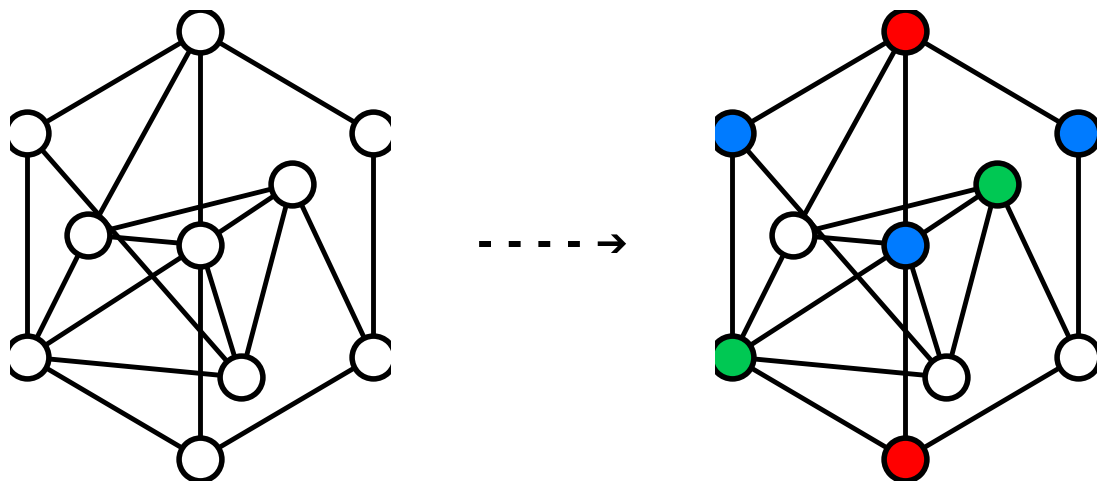

In [16]:
import random
import matplotlib.pyplot as plt

# ==============================================================================
# 1. GRAPH TOPOLOGY & NODE LAYOUT
# Exact 10-node topology matching the Canvas assignment screenshot
# ==============================================================================
NODES = {
    0: (0.50, 0.92),  # Top Outer (Blue)
    1: (0.16, 0.72),  # Top-Left Outer (Red)
    2: (0.84, 0.72),  # Top-Right Outer (White)
    3: (0.16, 0.28),  # Bottom-Left Outer (White)
    4: (0.84, 0.28),  # Bottom-Right Outer (Red)
    5: (0.50, 0.08),  # Bottom Outer (Blue)
    6: (0.50, 0.50),  # Center Node (Green)
    7: (0.28, 0.52),  # Mid-Left Inner (White)
    8: (0.68, 0.62),  # Upper-Right Inner (Blue)
    9: (0.58, 0.24)   # Lower-Right Inner (Red)
}

# Exact 19 Edges drawn in both input and output graphs
EDGES = [
    # Outer Hexagon Perimeter
    (0, 1), (0, 2), (2, 4), (4, 5), (5, 3), (3, 1),

    # Vertical Central Spine
    (0, 6), (6, 5),

    # Center Green Node Star Connections
    (6, 7), (6, 8), (6, 9), (6, 3),

    # Internal Diagonal & Cross Lines
    (0, 7), (1, 9), (7, 8), (7, 3),
    (8, 4), (8, 9), (3, 9)
]

# Palette mapping matching assignment picture: 0=White, 1=Blue, 2=Red, 3=Green
COLOR_PALETTE = ["#ffffff", "#007bff", "#ff0000", "#00c853"]
COLOR_NAMES = ["White", "Blue", "Red", "Green"]


# ==============================================================================
# 2. CODEEVOLVE GENETIC ALGORITHM ENGINE
# ==============================================================================
def count_edge_conflicts(individual):
    """Calculates penalty: counts adjacent nodes sharing the exact same color."""
    return sum(1 for u, v in EDGES if individual[u] == individual[v])


def run_codeevolve_ga(pop_size=50, generations=300, mutation_rate=0.08):
    """
    CodeEvolve evolutionary search loop:
    Encodes solutions as 10-element chromosomes, applying selection,
    crossover, mutation, and elitism to converge on 0 edge conflicts.
    """
    # Initialize random population: each gene in {0: White, 1: Blue, 2: Red, 3: Green}
    population = [[random.choice([0, 1, 2, 3]) for _ in range(10)] for _ in range(pop_size)]

    best_overall_chrom = None
    min_overall_conflicts = float('inf')

    for gen in range(1, generations + 1):
        conflicts = [count_edge_conflicts(ind) for ind in population]
        min_c = min(conflicts)
        best_idx = conflicts.index(min_c)

        # Track global best solution found by CodeEvolve
        if min_c < min_overall_conflicts:
            min_overall_conflicts = min_c
            best_overall_chrom = population[best_idx].copy()

        # Stop early if a perfect 0-conflict coloring is found
        if min_c == 0:
            print(f"CodeEvolve found a valid 0-conflict 3-coloring at Generation {gen}!")
            return population[best_idx], 0, gen

        # Calculate fitness (higher score = fewer conflicts)
        fitnesses = [100.0 / (1.0 + c) for c in conflicts]

        # Elitism: preserve the fittest individual into the next generation
        new_pop = [population[best_idx].copy()]

        # Generate offspring
        while len(new_pop) < pop_size:
            # Tournament Selection (k=3)
            p1 = population[max(random.sample(range(pop_size), 3), key=lambda i: fitnesses[i])]
            p2 = population[max(random.sample(range(pop_size), 3), key=lambda i: fitnesses[i])]

            # Single-point Crossover
            crossover_point = random.randint(1, 9)
            child = p1[:crossover_point] + p2[crossover_point:]

            # Bit-flip Mutation
            child = [random.choice([0, 1, 2, 3]) if random.random() < mutation_rate else gene for gene in child]
            new_pop.append(child)

        population = new_pop

    return best_overall_chrom, min_overall_conflicts, generations


# ==============================================================================
# 3. VISUALIZATION ENGINE (EXACT MATCH TO ASSIGNMENT SCREENSHOT)
# ==============================================================================
def render_assignment_figure(solution_colors):
    """Renders the uncolored input graph, dotted transition arrow, and solved graph."""
    fig, (ax_left, ax_arrow, ax_right) = plt.subplots(
        1, 3, figsize=(13, 5), gridspec_kw={'width_ratios': [1, 0.25, 1]}
    )

    def draw_graph_panel(ax, node_color_indices, title):
        ax.set_aspect('equal')

        # Draw thick black edge lines
        for u, v in EDGES:
            p1, p2 = NODES[u], NODES[v]
            ax.plot([p1[0], p2[0]], [p1[1], p2[1]], color="black", linewidth=3.5, zorder=1)

        # Draw nodes with thick black borders
        for node_id, (x, y) in NODES.items():
            color_hex = "#ffffff" if node_color_indices is None else COLOR_PALETTE[node_color_indices[node_id]]
            ax.scatter(x, y, color=color_hex, s=950, edgecolors="black", linewidths=4, zorder=2)

        ax.axis("off")

    # Left: Uncolored Input Graph
    draw_graph_panel(ax_left, None, "Uncolored Input Graph")

    # Center: Transition Arrow
    ax_arrow.text(0.5, 0.5, "- - - - ➔", fontsize=28, fontweight="bold", ha="center", va="center")
    ax_arrow.axis("off")

    # Right: Solved Colored Graph
    draw_graph_panel(ax_right, solution_colors, "Solved Output Graph")

    plt.tight_layout()
    plt.show()


# ==============================================================================
# 4. EXECUTION ENTRY POINT
# ==============================================================================
if __name__ == "__main__":
    random.seed(42)

    print("Executing CodeEvolve Graph Coloring Solver...")
    solution_chrom, conflicts, gens = run_codeevolve_ga()

    print("\n" + "=" * 50)
    print("         CODEEVOLVE OPTIMIZATION SUMMARY          ")
    print("=" * 50)
    for node_id, color_idx in enumerate(solution_chrom):
        print(f"  Node {node_id:2d} --> {COLOR_NAMES[color_idx]}")
    print("-" * 50)
    print(f"  Total Edge Conflicts : {conflicts}")
    print(f"  Generations Elapsed  : {gens}")
    print("=" * 50 + "\n")

    # Render side-by-side graphical output
    render_assignment_figure(solution_chrom)